In [1]:
%load_ext autoreload
%autoreload 2

import jax
jax.config.update("jax_enable_x64", True)

from mGST.low_level_jit import cost_function_jax_mps
from mGST.utility_functions_comparisons import GSTConfiguration, get_full_mgst_parameters_from_configuration, get_initial_gate_set_for_optimization
from mGST.trust_region import run_riemannian_optimization, are_all_tensors_in_gate_set_isometries
from mGST.typing import OperatorSchedule, TrustRegionOptions
from mGST.visualization import plot_cost_function

backend = "iqmfakeapollo"

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
num_seq = 1000
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim
povm_rank = dim
kraus_rank = 4
num_shots = 1000

title_init = rf"{num_qubits}Q | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Random Noisy Gate Set | Shots: {num_shots}"

In [3]:
config = GSTConfiguration(
    qubit_layouts=[[0, 1]],
    gate_set="2QXYICZ",
    num_circuits=num_seq,
    shots=num_shots,
    rank=kraus_rank,
)

kraus_tensor_mgst, kraus_mgst, povm_mgst, state_mgst, prob_matrix, indices_list, additional_mgst_vars = get_full_mgst_parameters_from_configuration(
    config, backend, only_jax_variables=False
)

target_gate_set_superops = {
    "kraus": kraus_mgst,
    "povm": povm_mgst,
    "state": state_mgst
}

cost_fn_kwargs = {
    "indices_list": indices_list,
    "prob_matrix": prob_matrix,
    "jit": True,
    "use_log_likelihood": True,
    "verbose": False,  # we don't want to print during the cost function evaluation
    "num_shots": num_shots,
}

2026-10-27 09:35:39,190 - iqm.benchmarks.logging_config - INFO - Generating 1000 random GST circuits
2026-10-27 09:35:39,905 - iqm.benchmarks.logging_config - INFO - Will transpile all 1000 circuits according to fixed physical layout
2026-10-27 09:35:40,322 - iqm.benchmarks.logging_config - INFO - Transpiling for backend IQMFakeApolloBackend with optimization level 0, sabre routing method all circuits
2026-10-27 09:35:44,228 - iqm.benchmarks.logging_config - INFO - Submitting batch with 1000 circuits corresponding to qubits [0, 1]
2026-10-27 09:35:44,242 - iqm.benchmarks.logging_config - INFO - Stored jobs for 1 layouts in dataset
2026-10-27 09:35:44,302 - iqm.benchmarks.logging_config - INFO - Now executing the corresponding circuit batch
2026-10-27 09:35:44,364 - iqm.benchmarks.logging_config - INFO - Retrieving all counts
2026-10-27 09:35:46,124 - iqm.benchmarks.logging_config - INFO - Adding counts to dataset
2026-10-27 09:35:48,470 - iqm.benchmarks.logging_config - INFO - Run comp

In [4]:
spam_depolarization = 1e-2

init_gate_set_psd_interior = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    # the rank-4 truncation of the perturbed (full-rank) channel leaves |sum K^†K - I| ~ 5e-6
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_interior))

All isometries: True


In [5]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-3 # changed due to the changes in convergence criteria
global_gradient_norm_tol = 1e-10

tr_options_distance = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=False, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="typical_distance")

schedule_distance = OperatorSchedule.default(num_iterations_outer, tr_options_distance)

optimization_schedule = {op: schedule_distance for op in ["povm", "kraus", "state"]}

optimization_options = {
    "optimization_schedule": optimization_schedule,
    "num_iterations": num_iterations_outer,
    "relative_precision": relative_precision, 
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "carry_over_radius": True,
    "absolute_tolerance": 1, # for the log likelihood convergence
    "verbose": True,
}

In [6]:
# Same options as the baseline run above, only the initial POVM and state differ.
optimized_operators_rank_4, cost_fn_history_rank_4, convergence_reason_rank_4 = run_riemannian_optimization(
    *init_gate_set_psd_interior.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.094618e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 2.50e-01. Δmax = 2.00e+00
TR Iteration: 0. f(x): 1.130884e+06. |r∇f(x)|: 5.461012e+04. Radius: 2.50e-01
TR Iteration: 1. f(x): 1.119026e+06. |r∇f(x)|: 4.448754e+04. Radius: 5.00e-01
TR Iteration: 2. f(x): 1.117394e+06. |r∇f(x)|: 5.976787e+04. Radius: 1.25e-01
TR Iteration: 3. f(x): 1.112428e+06. |r∇f(x)|: 2.521021e+04. Radius: 2.50e-01
TR Iteration: 4. f(x): 1.110850e+06. |r∇f(x)|: 3.878168e+03. Radius: 2.50e-01
Optimizatio

In [10]:
init_gate_set_psd_rank_16 = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=16,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_rank_16))

All isometries: True


In [11]:
optimized_operators_rank_16, cost_fn_history_rank_16, convergence_reason_rank_16 = run_riemannian_optimization(
    *init_gate_set_psd_rank_16.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.094618e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 2.50e-01. Δmax = 2.00e+00
TR Iteration: 0. f(x): 1.119473e+06. |r∇f(x)|: 5.562355e+04. Radius: 2.50e-01
TR Iteration: 1. f(x): 1.106053e+06. |r∇f(x)|: 4.438486e+04. Radius: 2.50e-01
TR Iteration: 2. f(x): 1.100252e+06. |r∇f(x)|: 1.627941e+04. Radius: 5.00e-01
TR Iteration: 3. f(x): 1.099185e+06. |r∇f(x)|: 4.473330e+03. Radius: 5.00e-01
TR Iteration: 4. f(x): 1.099051e+06. |r∇f(x)|: 1.088514e+03. Radius: 5.00e-01
Optimizatio

In [7]:
init_gate_set_psd_rank_1 = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=1,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_rank_1))

All isometries: True


In [8]:
optimized_operators_rank_1, cost_fn_history_rank_1, convergence_reason_rank_1 = run_riemannian_optimization(
    *init_gate_set_psd_rank_1.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.094618e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 2.50e-01. Δmax = 2.00e+00
TR Iteration: 0. f(x): 1.153598e+06. |r∇f(x)|: 9.094604e+04. Radius: 2.50e-01
TR Iteration: 1. f(x): 1.132060e+06. |r∇f(x)|: 7.221491e+04. Radius: 5.00e-01
TR Iteration: 2. f(x): 1.122017e+06. |r∇f(x)|: 4.649420e+04. Radius: 5.00e-01
TR Iteration: 3. f(x): 1.118129e+06. |r∇f(x)|: 5.241357e+03. Radius: 5.00e-01
TR Iteration: 4. f(x): 1.117932e+06. |r∇f(x)|: 1.425470e+03. Radius: 5.00e-01
Optimizatio

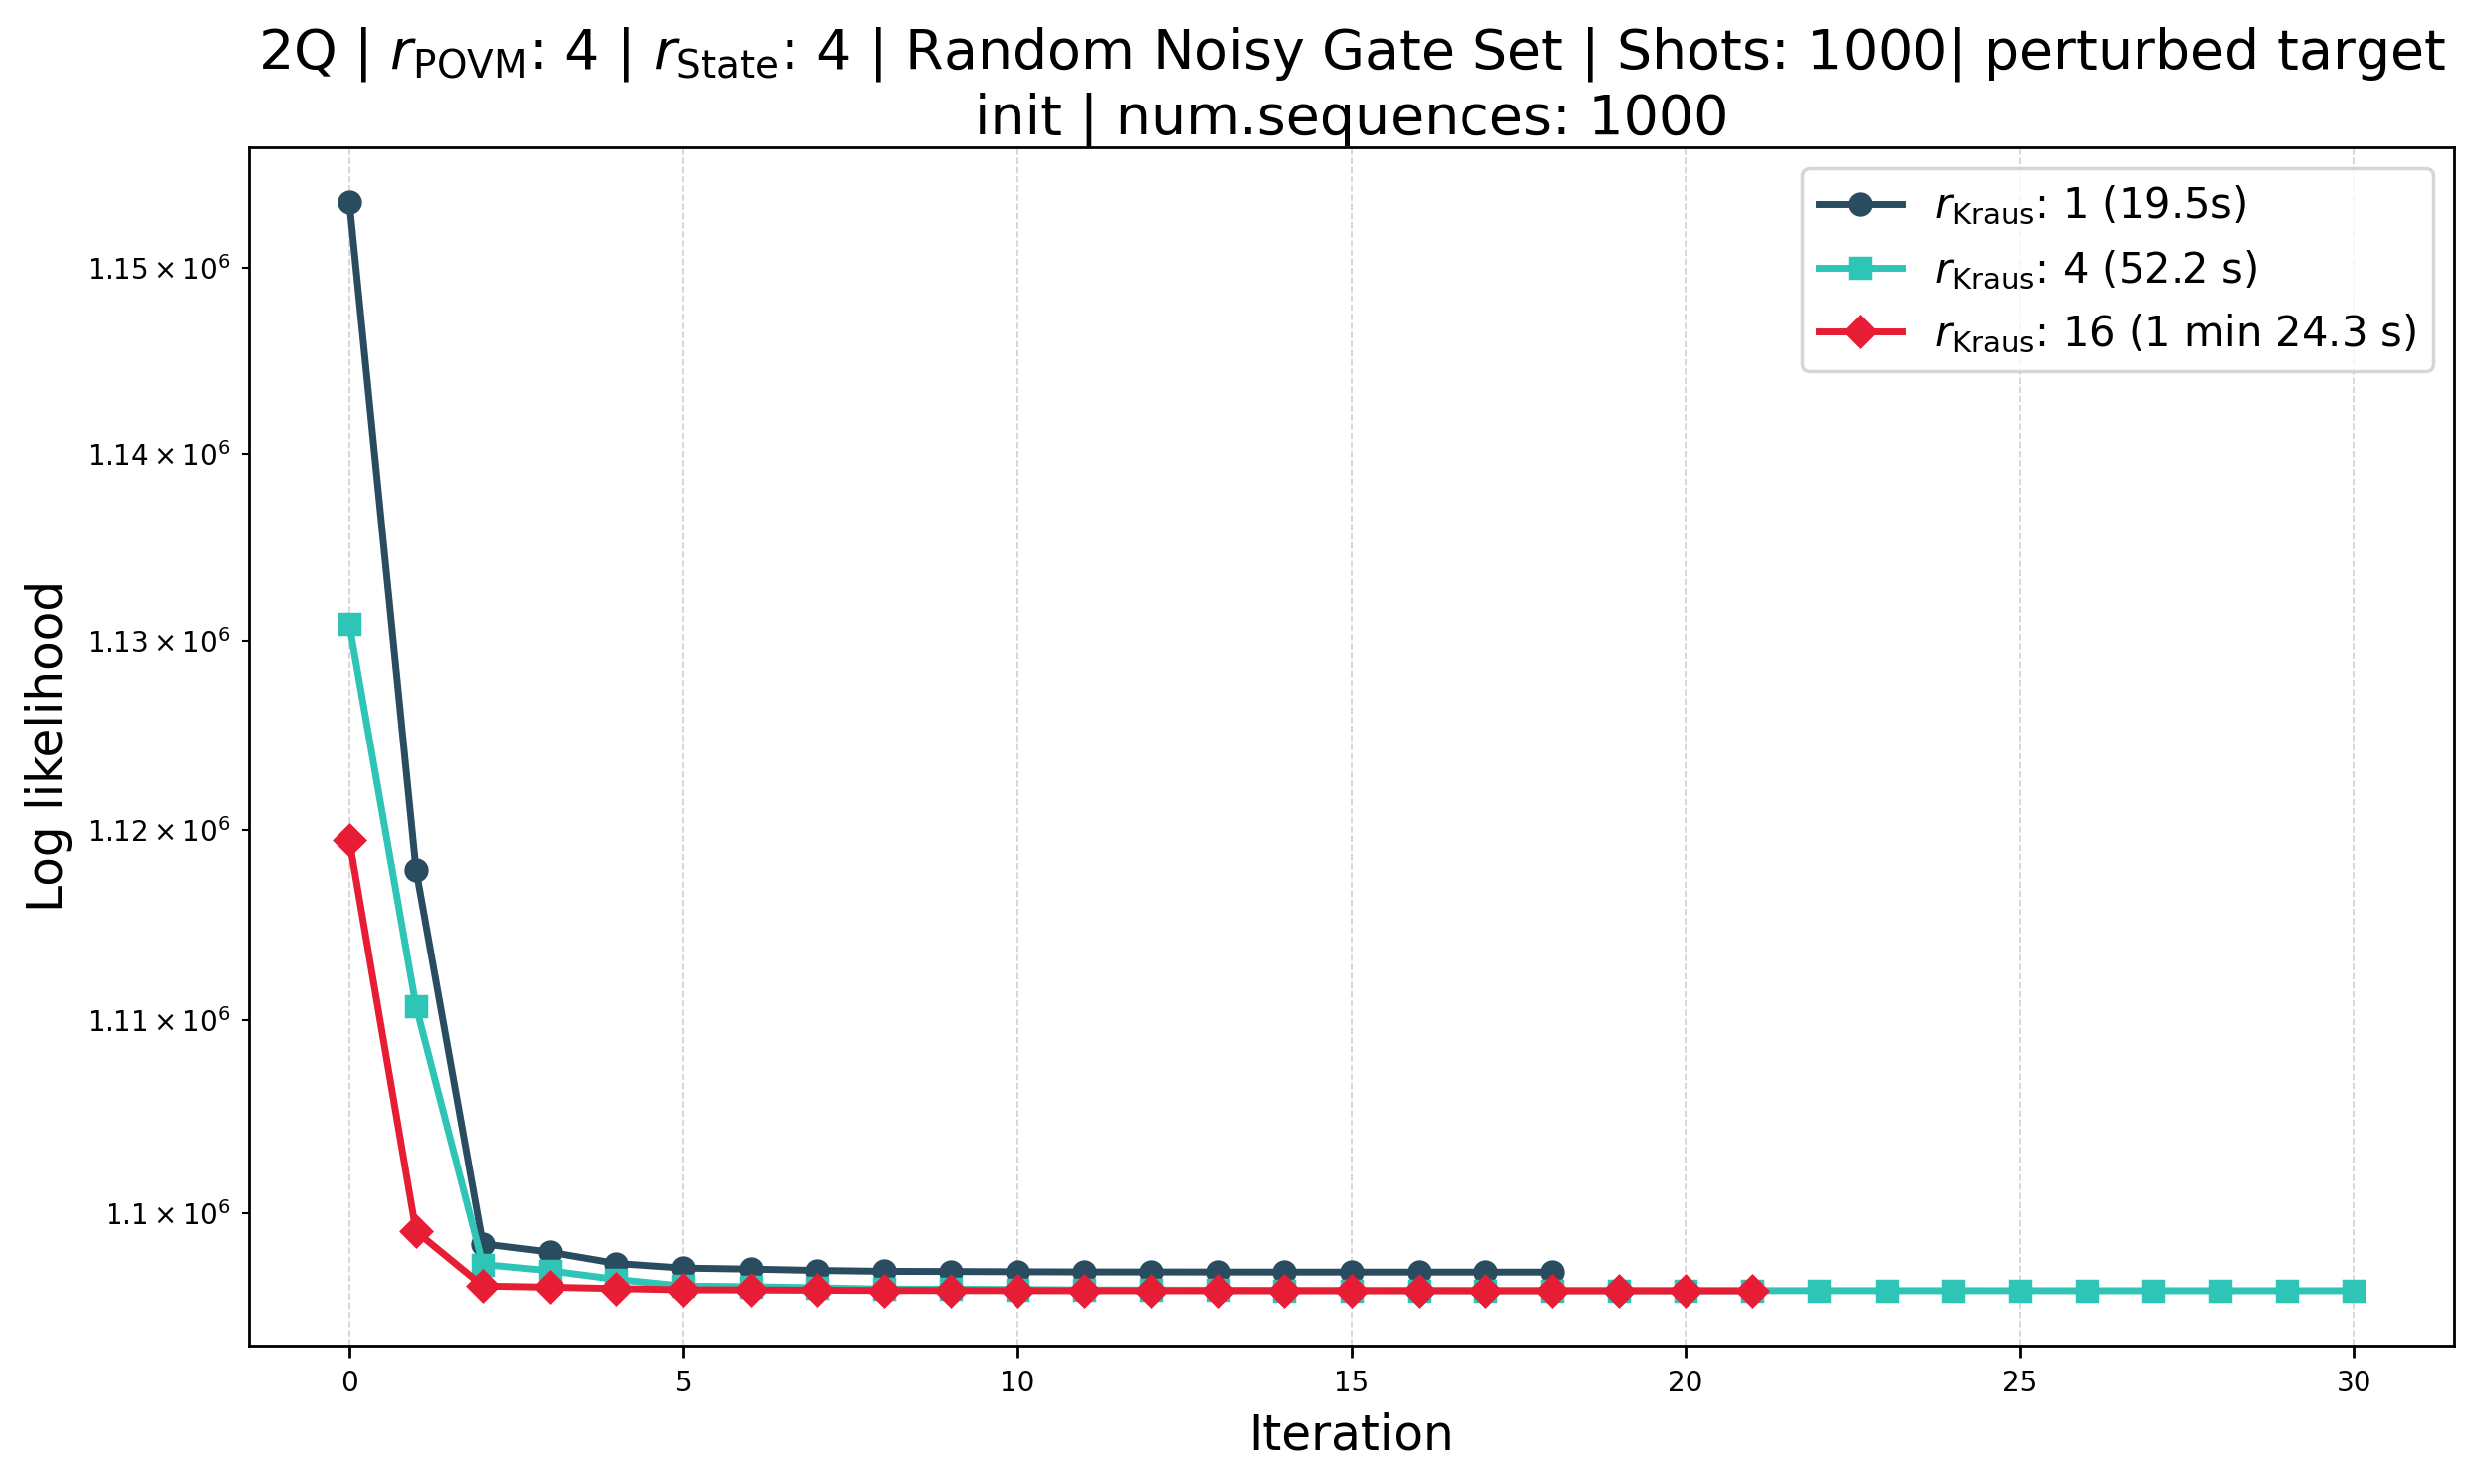

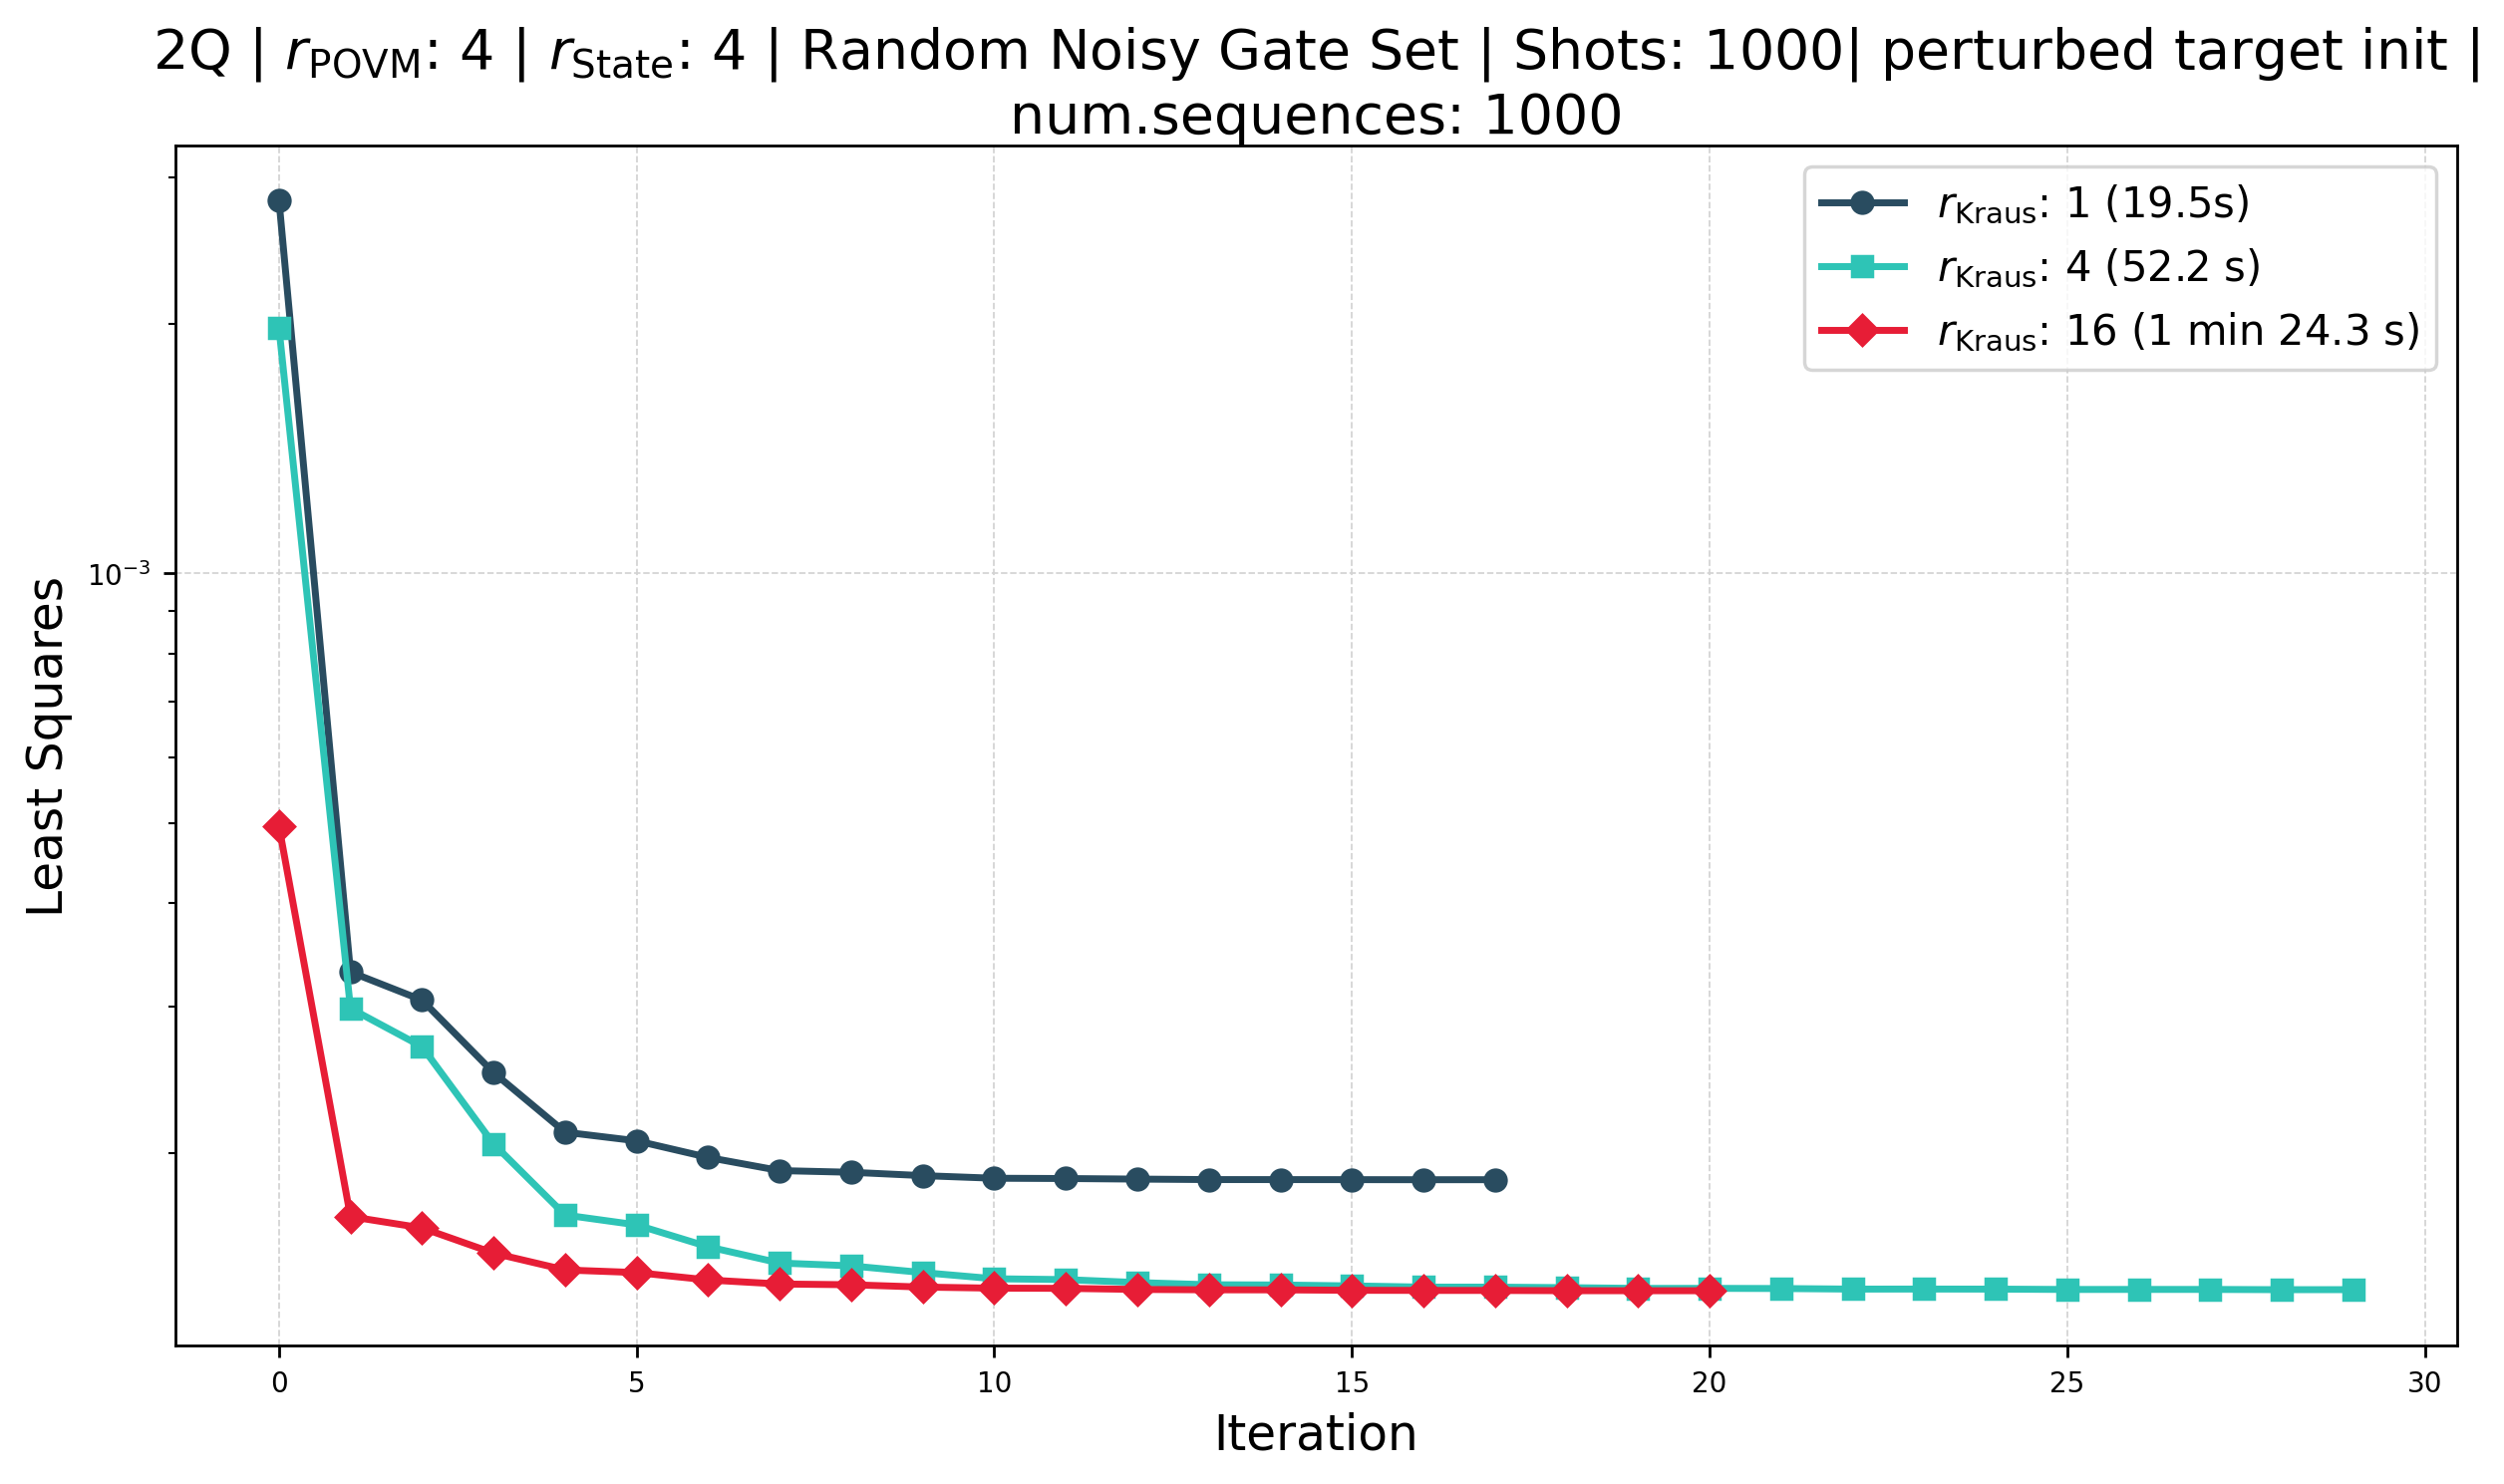

In [16]:
labels = [rf"$r_\mathrm{{Kraus}}$: 1 (19.5s)", rf"$r_\mathrm{{Kraus}}$: 4 (52.2 s)", rf"$r_\mathrm{{Kraus}}$: 16 (1 min 24.3 s)"]

title_comparison = title_init + f"| perturbed target init | num.sequences: {num_seq}"

cost_fns = [cost_fn_history_rank_1, cost_fn_history_rank_4, cost_fn_history_rank_16]
cost_loglikelihoods = [cost["main"] for cost in cost_fns]
cost_least_squares = [cost["least_squares"] for cost in cost_fns]

plot_cost_function(cost_loglikelihoods, title=title_comparison, labels=labels, ylabel="Log likelihood")

plot_cost_function(cost_least_squares, title=title_comparison, labels=labels, ylabel="Least Squares")